# Module 4: 4-bit Quantum Adder

This notebook extends the full-adder design in the class notebook `QC_Ekert_FA1bit_and_2bit_examp.ipynb` to add two 4-bit binary numbers using Qiskit. It reuses the class notebook's `carry`, `carry_rev`, and `sum` functions.

Each input is an unsigned integer from 0 to 15, encoded as four binary bits. The output has five bits so that the final carry is retained: for example, `1111 + 1111 = 11110` (15 + 15 = 30).

The code requires `qiskit`, `matplotlib`, and `pylatexenc` (for the circuit drawing).

In [1]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

## Full-adder functions from the class notebook

These three gate sequences are reused unchanged.

In [2]:
# Define functions for the ripple carry adder.
def sum(circ, cin, a, b):
    circ.cx(a,b)
    circ.cx(cin,b)

def carry(circ, cin, a, b, cout):
    circ.ccx(a, b, cout)
    circ.cx(a, b)
    circ.ccx(cin, b, cout)

def carry_rev(circ, cin, a, b, cout):
    circ.ccx(cin, b, cout)
    circ.cx(a, b)
    circ.ccx(a, b, cout)


## Extending the design to four bits

The circuit uses 13 qubits. Each bit position has a carry qubit, an `a` qubit, and a `b` qubit. The `b` qubits become the four sum bits; qubit 12 holds the final carry.

| Bit position | Carry input | Input A | Input B / sum |
|---|---|---|---|
| 0 (least significant) | q0 | q1 | q2 |
| 1 | q3 | q4 | q5 |
| 2 | q6 | q7 | q8 |
| 3 (most significant) | q9 | q10 | q11 |

All carry qubits start at zero. The `carry` block runs through the four positions. At the most significant position, a CNOT undoes the change made by `carry` before `sum` writes the top sum bit. The circuit then runs `carry_rev` and `sum` backward through the lower positions, restoring intermediate carry qubits to zero.

The circuit measures q2, q5, q8, and q11 into classical bits 0 through 3, and q12 into bit 4. The displayed result is therefore `carry s3 s2 s1 s0`, read directly as a five-bit binary number.

In [3]:
N_BITS = 4  # width of the adder


def c_q(i):
    """Qubit holding carry c_i."""
    return 3 * i


def a_q(i):
    """Qubit holding a_i."""
    return 3 * i + 1


def b_q(i):
    """Qubit holding b_i (overwritten with sum bit s_i)."""
    return 3 * i + 2


def encode(circ, value, qubit_of, n):
    """Load an n-bit integer into a register with X gates (bit 0 = LSB)."""
    for i in range(n):
        if (value >> i) & 1:
            circ.x(qubit_of(i))


def add_ripple_adder(circ, n):
    """Append the n-bit ripple-carry adder |a,b,0> -> |a,a+b> to circ."""
    # 1) propagate carries upward
    for i in range(n):
        carry(circ, c_q(i), a_q(i), b_q(i), c_q(i + 1))
    circ.barrier()

    # 2) most significant bit: undo carry's CNOT, then compute its sum
    circ.cx(a_q(n - 1), b_q(n - 1))
    sum(circ, c_q(n - 1), a_q(n - 1), b_q(n - 1))
    circ.barrier()

    # 3) uncompute carries downward, writing each sum bit into b_i
    for i in range(n - 2, -1, -1):
        carry_rev(circ, c_q(i), a_q(i), b_q(i), c_q(i + 1))
        sum(circ, c_q(i), a_q(i), b_q(i))
    circ.barrier()


def build_adder(a, b):
    """Build the 4-bit adder for two integers in [0, 15]."""
    n = N_BITS
    if not (0 <= a < 2**n and 0 <= b < 2**n):
        raise ValueError(
            f"a and b must be in [0, {2**n - 1}] for an {n}-bit adder")

    qc = QuantumCircuit(3 * n + 1, n + 1)
    encode(qc, a, a_q, n)
    encode(qc, b, b_q, n)
    qc.barrier()

    add_ripple_adder(qc, n)

    # sum bit s_i -> clbit i, final carry -> clbit n, so the measured
    # bitstring (printed MSB first) is the binary value of a + b
    for i in range(n):
        qc.measure(b_q(i), i)
    qc.measure(c_q(n), n)
    return qc


def run_counts(circuits, shots=1024):
    """Run circuits on the sampler; return a list of count dicts."""
    if isinstance(circuits, QuantumCircuit):
        circuits = [circuits]
    job = StatevectorSampler().run(circuits, shots=shots)
    return [res.data.c.get_counts() for res in job.result()]

## The 4-bit circuit

Example inputs: `1011` (11) and `0110` (6). The expected output is `10001` (17).

4-bit adder: 13 qubits, 5 output bits


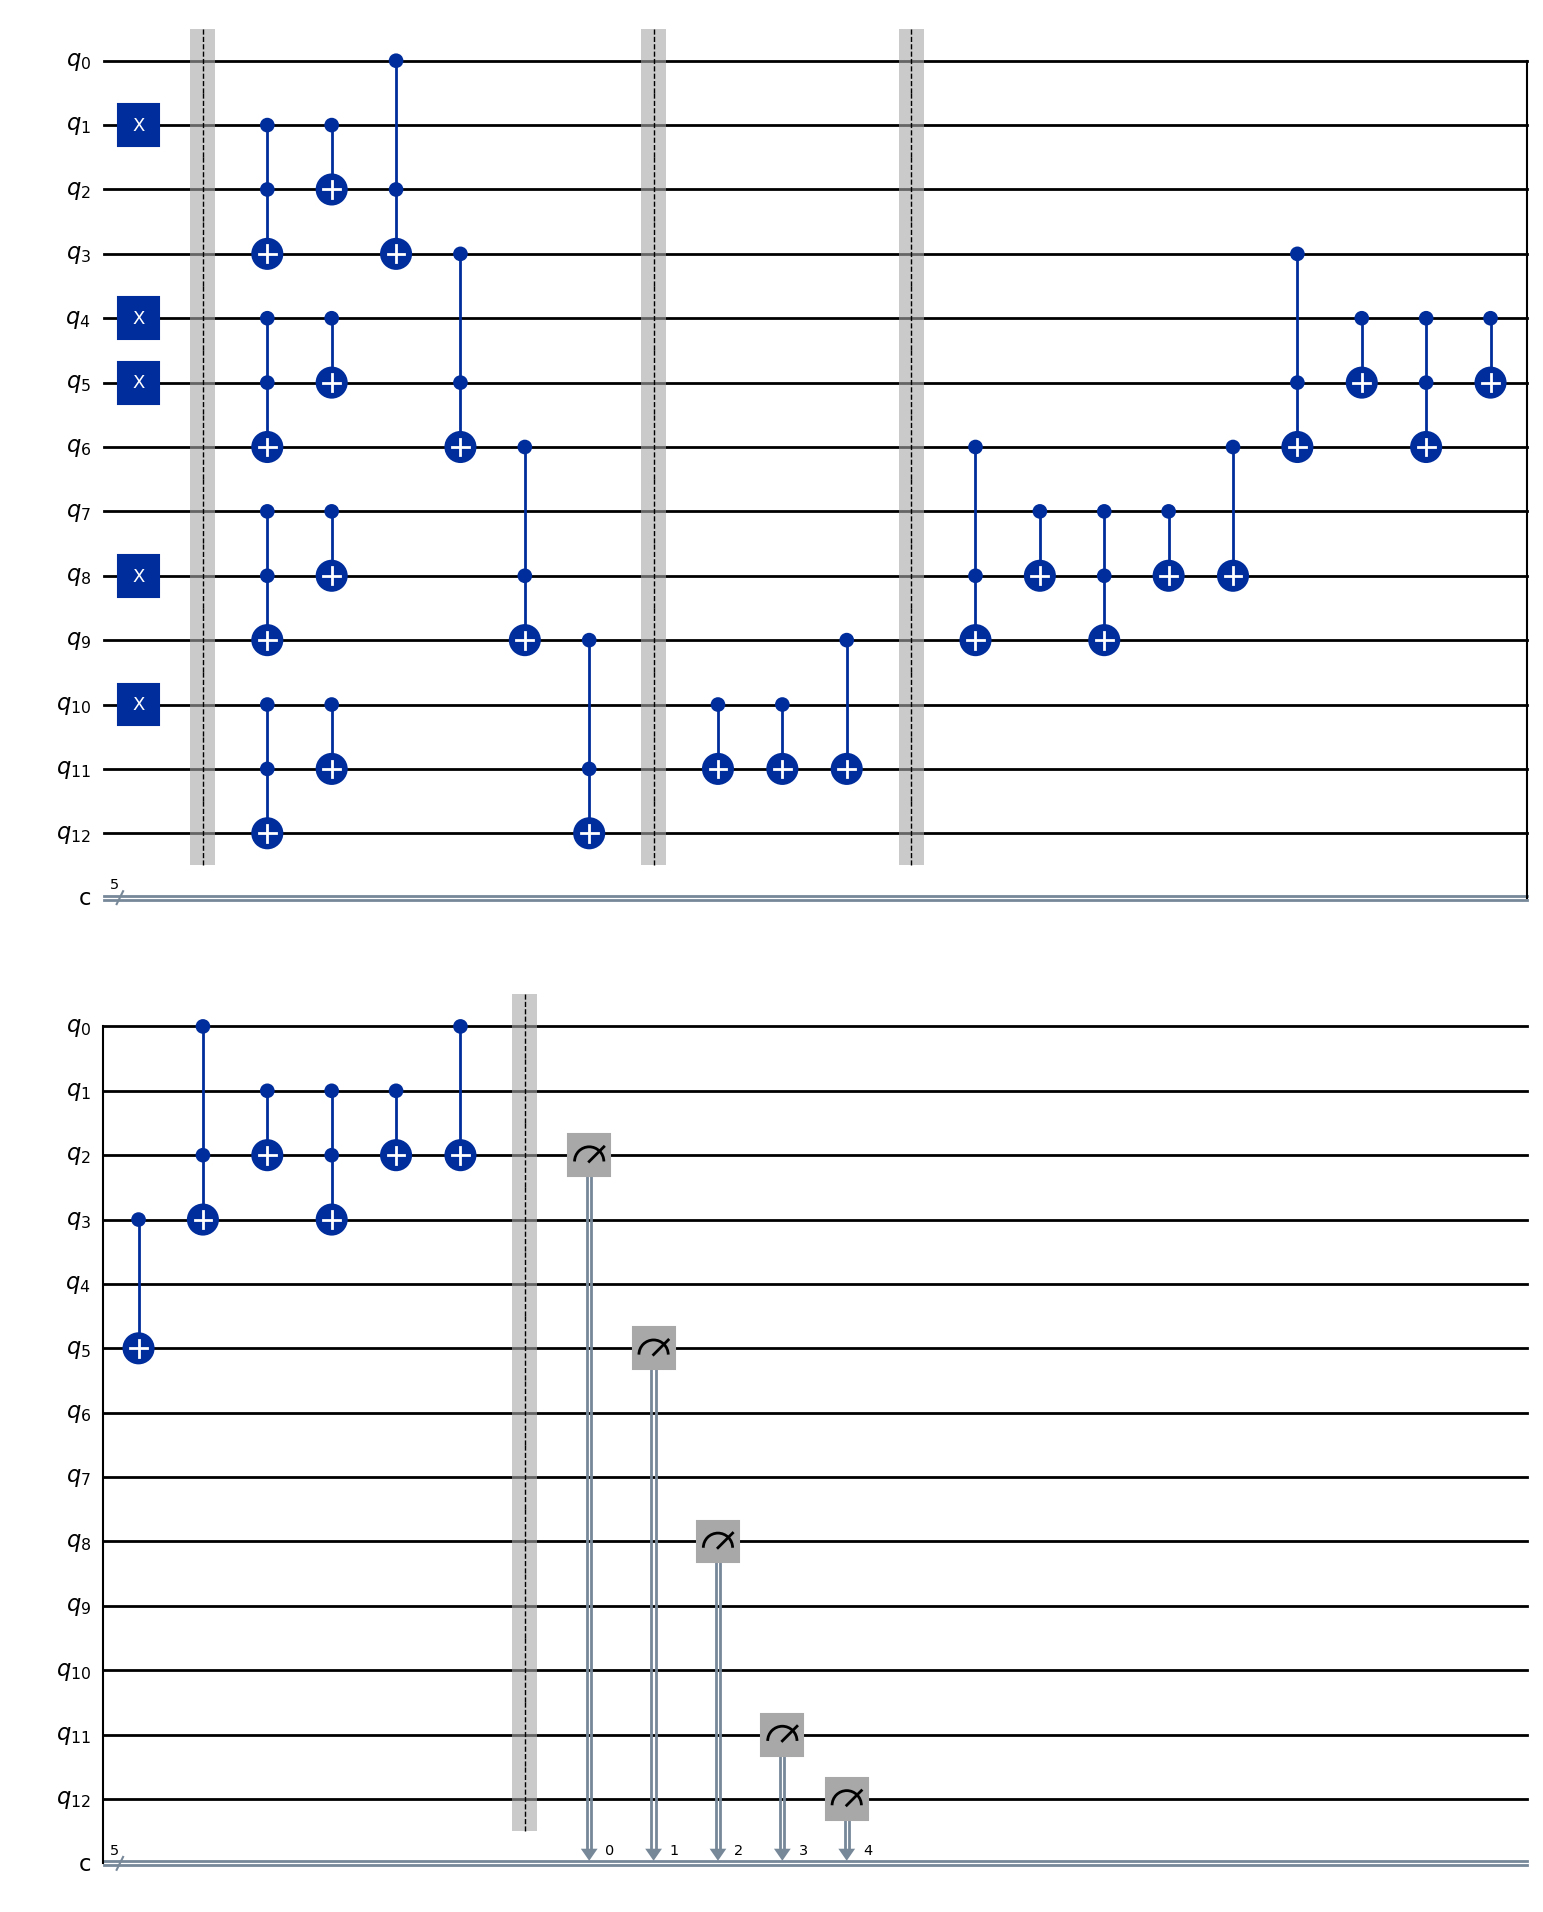

In [4]:
qc = build_adder(11, 6)
print(f"4-bit adder: {qc.num_qubits} qubits, {qc.num_clbits} output bits")
qc.draw("mpl", fold=22)

## Test cases and histograms

Each test below adds two four-bit binary inputs with the Qiskit circuit. Its own output lists the expected sum, measured sum, shot counts, and PASS or FAIL result, followed immediately by its histogram.

The eight cases cover zero, additions without carries, carry propagation, the final carry, and the largest four-bit inputs. Every circuit runs for 1024 shots using the ideal `StatevectorSampler`. The shared function below runs and checks one test at a time.

In [5]:
SHOTS = 1024


def test_adder(a, b, label):
    """Run one 4-bit addition, print its result, and draw its histogram."""
    counts = run_counts(build_adder(a, b), shots=SHOTS)[0]
    expected = f"{a + b:05b}"
    measured = max(counts, key=counts.get)
    passed = counts == {expected: SHOTS}
    status = "PASS" if passed else "FAIL"

    print(f"Inputs: A = {a:04b} ({a}), B = {b:04b} ({b})")
    print(f"Expected sum: {expected} ({a + b})")
    print(f"Measured sum: {measured} ({int(measured, 2)})")
    print(f"Counts: {counts}")
    print(f"Result: {status}")
    assert passed, f"Incorrect result for {a:04b} + {b:04b}: {counts}"

    fig = plot_histogram(
        counts,
        title=f"{label}\n{a:04b} + {b:04b} = {expected}",
        figsize=(6.4, 3.4),
    )
    fig.tight_layout()
    plt.close(fig)
    return fig

### Test case 1: Zero inputs

Inputs: `0000` (0) and `0000` (0). Expected sum: `00000` (0).

Inputs: A = 0000 (0), B = 0000 (0)
Expected sum: 00000 (0)
Measured sum: 00000 (0)
Counts: {'00000': 1024}
Result: PASS


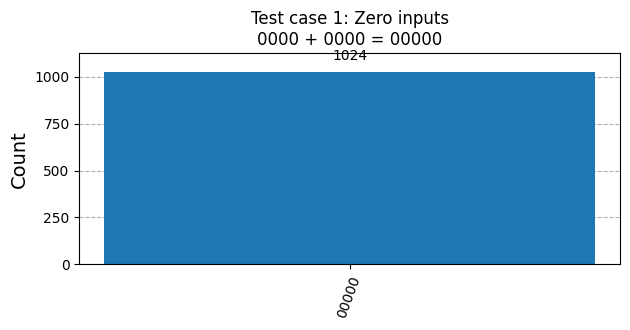

In [6]:
test_adder(0b0000, 0b0000, "Test case 1: Zero inputs")

### Test case 2: Carry through lower positions

Inputs: `0101` (5) and `0011` (3). Expected sum: `01000` (8).

Inputs: A = 0101 (5), B = 0011 (3)
Expected sum: 01000 (8)
Measured sum: 01000 (8)
Counts: {'01000': 1024}
Result: PASS


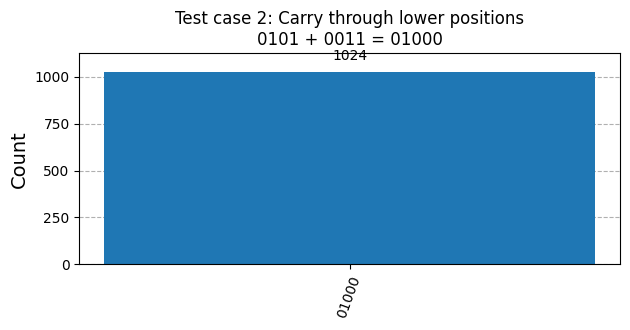

In [7]:
test_adder(0b0101, 0b0011, "Test case 2: Carry through lower positions")

### Test case 3: Addition without carries

Inputs: `1001` (9) and `0110` (6). Expected sum: `01111` (15).

Inputs: A = 1001 (9), B = 0110 (6)
Expected sum: 01111 (15)
Measured sum: 01111 (15)
Counts: {'01111': 1024}
Result: PASS


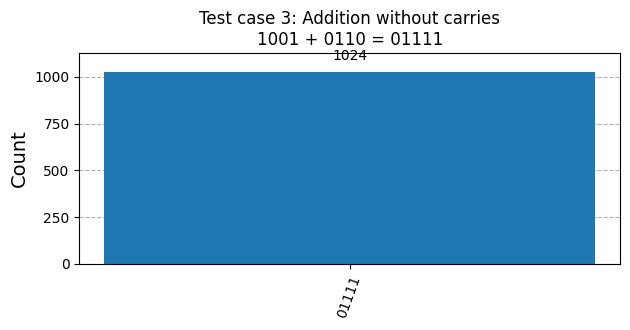

In [8]:
test_adder(0b1001, 0b0110, "Test case 3: Addition without carries")

### Test case 4: Another addition without carries

Inputs: `0111` (7) and `1000` (8). Expected sum: `01111` (15).

Inputs: A = 0111 (7), B = 1000 (8)
Expected sum: 01111 (15)
Measured sum: 01111 (15)
Counts: {'01111': 1024}
Result: PASS


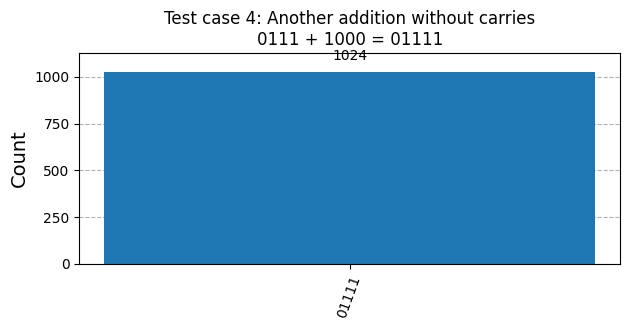

In [9]:
test_adder(0b0111, 0b1000, "Test case 4: Another addition without carries")

### Test case 5: Carry through all four positions

Inputs: `0001` (1) and `1111` (15). Expected sum: `10000` (16).

Inputs: A = 0001 (1), B = 1111 (15)
Expected sum: 10000 (16)
Measured sum: 10000 (16)
Counts: {'10000': 1024}
Result: PASS


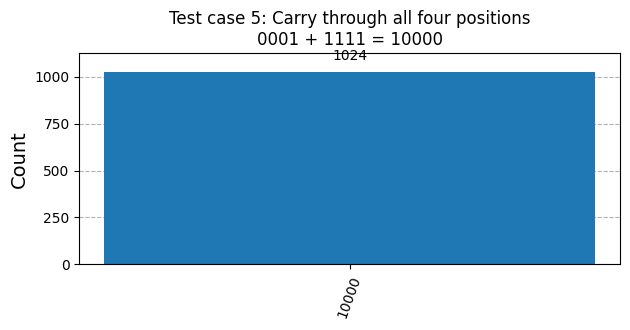

In [10]:
test_adder(0b0001, 0b1111, "Test case 5: Carry through all four positions")

### Test case 6: Final carry with a nonzero lower sum

Inputs: `1100` (12) and `1010` (10). Expected sum: `10110` (22).

Inputs: A = 1100 (12), B = 1010 (10)
Expected sum: 10110 (22)
Measured sum: 10110 (22)
Counts: {'10110': 1024}
Result: PASS


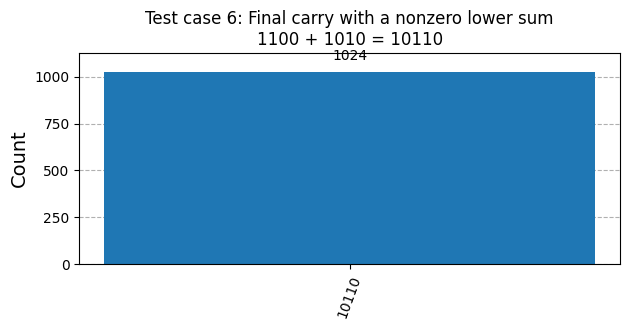

In [11]:
test_adder(0b1100, 0b1010, "Test case 6: Final carry with a nonzero lower sum")

### Test case 7: Largest four-bit inputs

Inputs: `1111` (15) and `1111` (15). Expected sum: `11110` (30).

Inputs: A = 1111 (15), B = 1111 (15)
Expected sum: 11110 (30)
Measured sum: 11110 (30)
Counts: {'11110': 1024}
Result: PASS


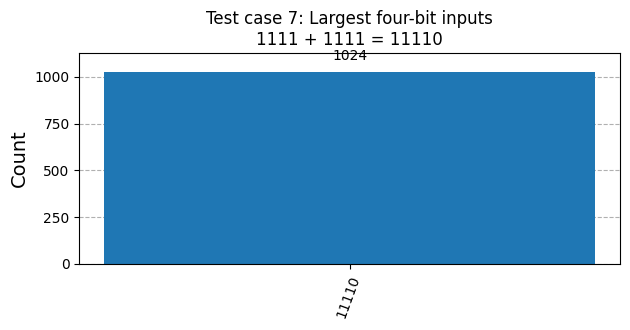

In [12]:
test_adder(0b1111, 0b1111, "Test case 7: Largest four-bit inputs")

### Test case 8: Carry from the most significant position

Inputs: `1000` (8) and `1000` (8). Expected sum: `10000` (16).

Inputs: A = 1000 (8), B = 1000 (8)
Expected sum: 10000 (16)
Measured sum: 10000 (16)
Counts: {'10000': 1024}
Result: PASS


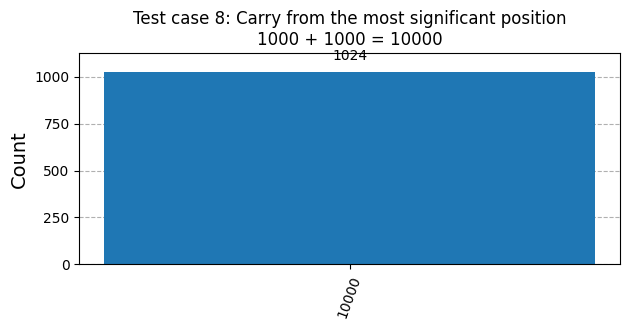

In [13]:
test_adder(0b1000, 0b1000, "Test case 8: Carry from the most significant position")

## Observations

These observations refer to the eight individual test cases and their corresponding histograms.

- **Zero inputs:** `0000 + 0000` produced `00000` (0 + 0 = 0).
- **Additions without carries:** `1001 + 0110` (9 + 6) and `0111 + 1000` (7 + 8) both produced `01111` (15), as expected.
- **Carry propagation:** `0101 + 0011` produced `01000` (5 + 3 = 8), showing a carry through the lower bit positions. `0001 + 1111` produced `10000` (1 + 15 = 16), showing a carry through all four positions into the fifth output bit.
- **Final carry and maximum inputs:** `1100 + 1010` produced `10110` (12 + 10 = 22), `1000 + 1000` produced `10000` (8 + 8 = 16), and `1111 + 1111` produced `11110` (15 + 15 = 30). The leading 1 in these five-bit results shows that the circuit retained the final carry. The 15 + 15 case tests the largest possible pair of four-bit inputs.
- **Agreement between expected and measured results:** Every test printed `PASS`. In each of the eight histograms, all 1024 shots appeared at the expected binary sum, with no other outcome observed in the ideal simulation.

## Summary

The implemented Qiskit circuit extends the class full-adder design to four bits using the same `carry`, `carry_rev`, and `sum` functions.

| Part of the answer | Result shown in this notebook |
|---|---|
| Circuit size | 13 qubits and 5 classical output bits |
| Test cases | 8 additions using four-bit binary inputs |
| Cases demonstrated | Zero, no carry, carry propagation, final carry, and maximum inputs |
| Expected versus measured sums | All 8 results matched; every case printed PASS |
| Histogram results | 1024 counts at the expected sum in each case |
| Largest tested addition | `1111 + 1111 = 11110` (15 + 15 = 30) |

The individual test outputs and histograms demonstrate correct addition for the eight tested input pairs. The fifth output bit preserves sums larger than 15, including the observed results 16, 22, and 30.